# Keeping a selected mathematical view

Suppose you have found a structure map that explains an interesting part of an encoded module. A figure lets someone see it. A saved view also records which parameters you selected, how they were drawn, and the mathematical values behind that picture. If you include the supported mathematical object, you can return to Julia and ask new questions.

We will explore a small finite encoding, keep three exact selections, and reopen them after closing the original inspector. A short ordinary-persistence variation then preserves one interval and its retained representative. You need Julia, TamerOp and CairoMakie; the cells use the repository's documentation environment. The [spaces-and-maps guide](../spaces_and_maps.md) supplies the mathematical context, but the example is constructed here in full.

The saved browser view has a finite set of prepared choices. Its state selector works without Julia or a network connection. New parameter queries belong to a resumed Julia session.


In [1]:
import TamerOp as OP
using CairoMakie
A = OP.Advanced


TamerOp.Advanced

## Start with the object behind the picture

Our module has a one-dimensional rational vector space on the closed square $[0,2]\times[0,2]$ and the zero space outside it. Comparable parameters inside the square are connected by identity maps.

The two regions and the coefficient below are an indicator presentation. `encode` constructs its finite poset, the module on that poset, and the assignment from parameters to finite labels. Keeping that assignment is what lets a later query recover the space at an original parameter.


In [2]:
options = A.EncodingOptions(; backend=:pl_backend,
    poset_kind=:signature, field=OP.CoreModules.QQField())
enc = OP.encode([A.BoxUpset([0, 0])], [A.BoxDownset([2, 2])],
    reshape(OP.QQ[1], 1, 1), options)
OP.describe(enc)


(kind = :encoding_result, poset_type = TamerOp.ZnEncoding.SignaturePoset{1, 1}, module_type = TamerOp.Modules.PModule{Rational{BigInt}, TamerOp.CoreModules.CoeffFields.QQField, Matrix{Rational{BigInt}}, TamerOp.ZnEncoding.SignaturePoset{1, 1}}, encoding_map_type = TamerOp.EncodingCore.CompiledEncoding{TamerOp.PLBackend.PLEncodingMapBoxes{2, 1, 1}, TamerOp.ZnEncoding.SignaturePoset{1, 1}, Nothing, Nothing, TamerOp.CoreModules.EncodingCache}, compiled = true, backend = :pl_backend, has_cohomology = true, has_presentation = true, module_dims = [0, 0, 1, 0], materialized = true, provenance = (category = :finite_poset_representations, base_poset = SignaturePoset(regions=4, flats=1, injectives=1), field = TamerOp.CoreModules.CoeffFields.QQField(), degree = nothing, degree_convention = :not_applicable, encoding = (map_type = TamerOp.EncodingCore.CompiledEncoding{TamerOp.PLBackend.PLEncodingMapBoxes{2, 1, 1}, TamerOp.ZnEncoding.SignaturePoset{1, 1}, Nothing, Nothing, TamerOp.CoreModules.Encodi

Choose two comparable interior parameters. Their finite labels come from this encoding; we do not assume label numbers. The resulting $1\times1$ matrix is the identity, so a nonzero vector continues as a nonzero vector.


In [3]:
x = (1//2, 1//2)
y = (3//2, 3//2)
classifier = OP.encoding_map(enc)
qx = A.locate(classifier, x)
qy = A.locate(classifier, y)
dimensions = OP.dimensions(enc)
selected_map = A.structure_map(OP.encoding_module(enc); source=qx, target=qy)
@assert dimensions[qx] == dimensions[qy] == 1
@assert selected_map == reshape(OP.QQ[1], 1, 1)
(source_dimension=dimensions[qx], target_dimension=dimensions[qy], map=selected_map)


(source_dimension = 1, target_dimension = 1, map = Rational{BigInt}[1;;])

## A selection joins geometry and algebra

An inspection session keeps the parameter picture, finite labels and selected algebra together. The viewing box only clips the drawing. We use rational coordinates, so the selection records the exact halves rather than coordinates inferred from a pointer click.

When we explore with continuous filtration or slice controls, the readout names
the committed parameter or line. A pending message means that a more recent
choice is being prepared while the previous answer remains visible. Rapid
movements replace waiting requests, and an obsolete answer cannot overwrite the
latest selection. The [source-cell guide](source_cells.ipynb) follows this through
cell activity; the [slice guide](slices_diagrams.ipynb) follows changing restrictions.

Exact entry remains useful even with these controls. A point close to a boundary
can give a different answer from a point on it, so a drawn cursor is not enough
to establish the distinction. Enter the required fraction, or use a retained
event button to reach the original grade. Before saving a view, wait for the
committed readout to show the intended choice: a saved state records the answer
currently displayed, rather than a request still waiting to complete.

`visual_state` freezes the current view, selection and declarative request. For a resumable inspector it also identifies the full supported mathematical source, which can materialize a lazy module and check its maps. This is more work than taking an ordinary static snapshot. Later selections in the live session do not change the frame. Here we render its static snapshot with CairoMakie; to control the running session in a browser, load WGLMakie and call `visualize(session; backend=:wglmakie)` while Julia remains available.


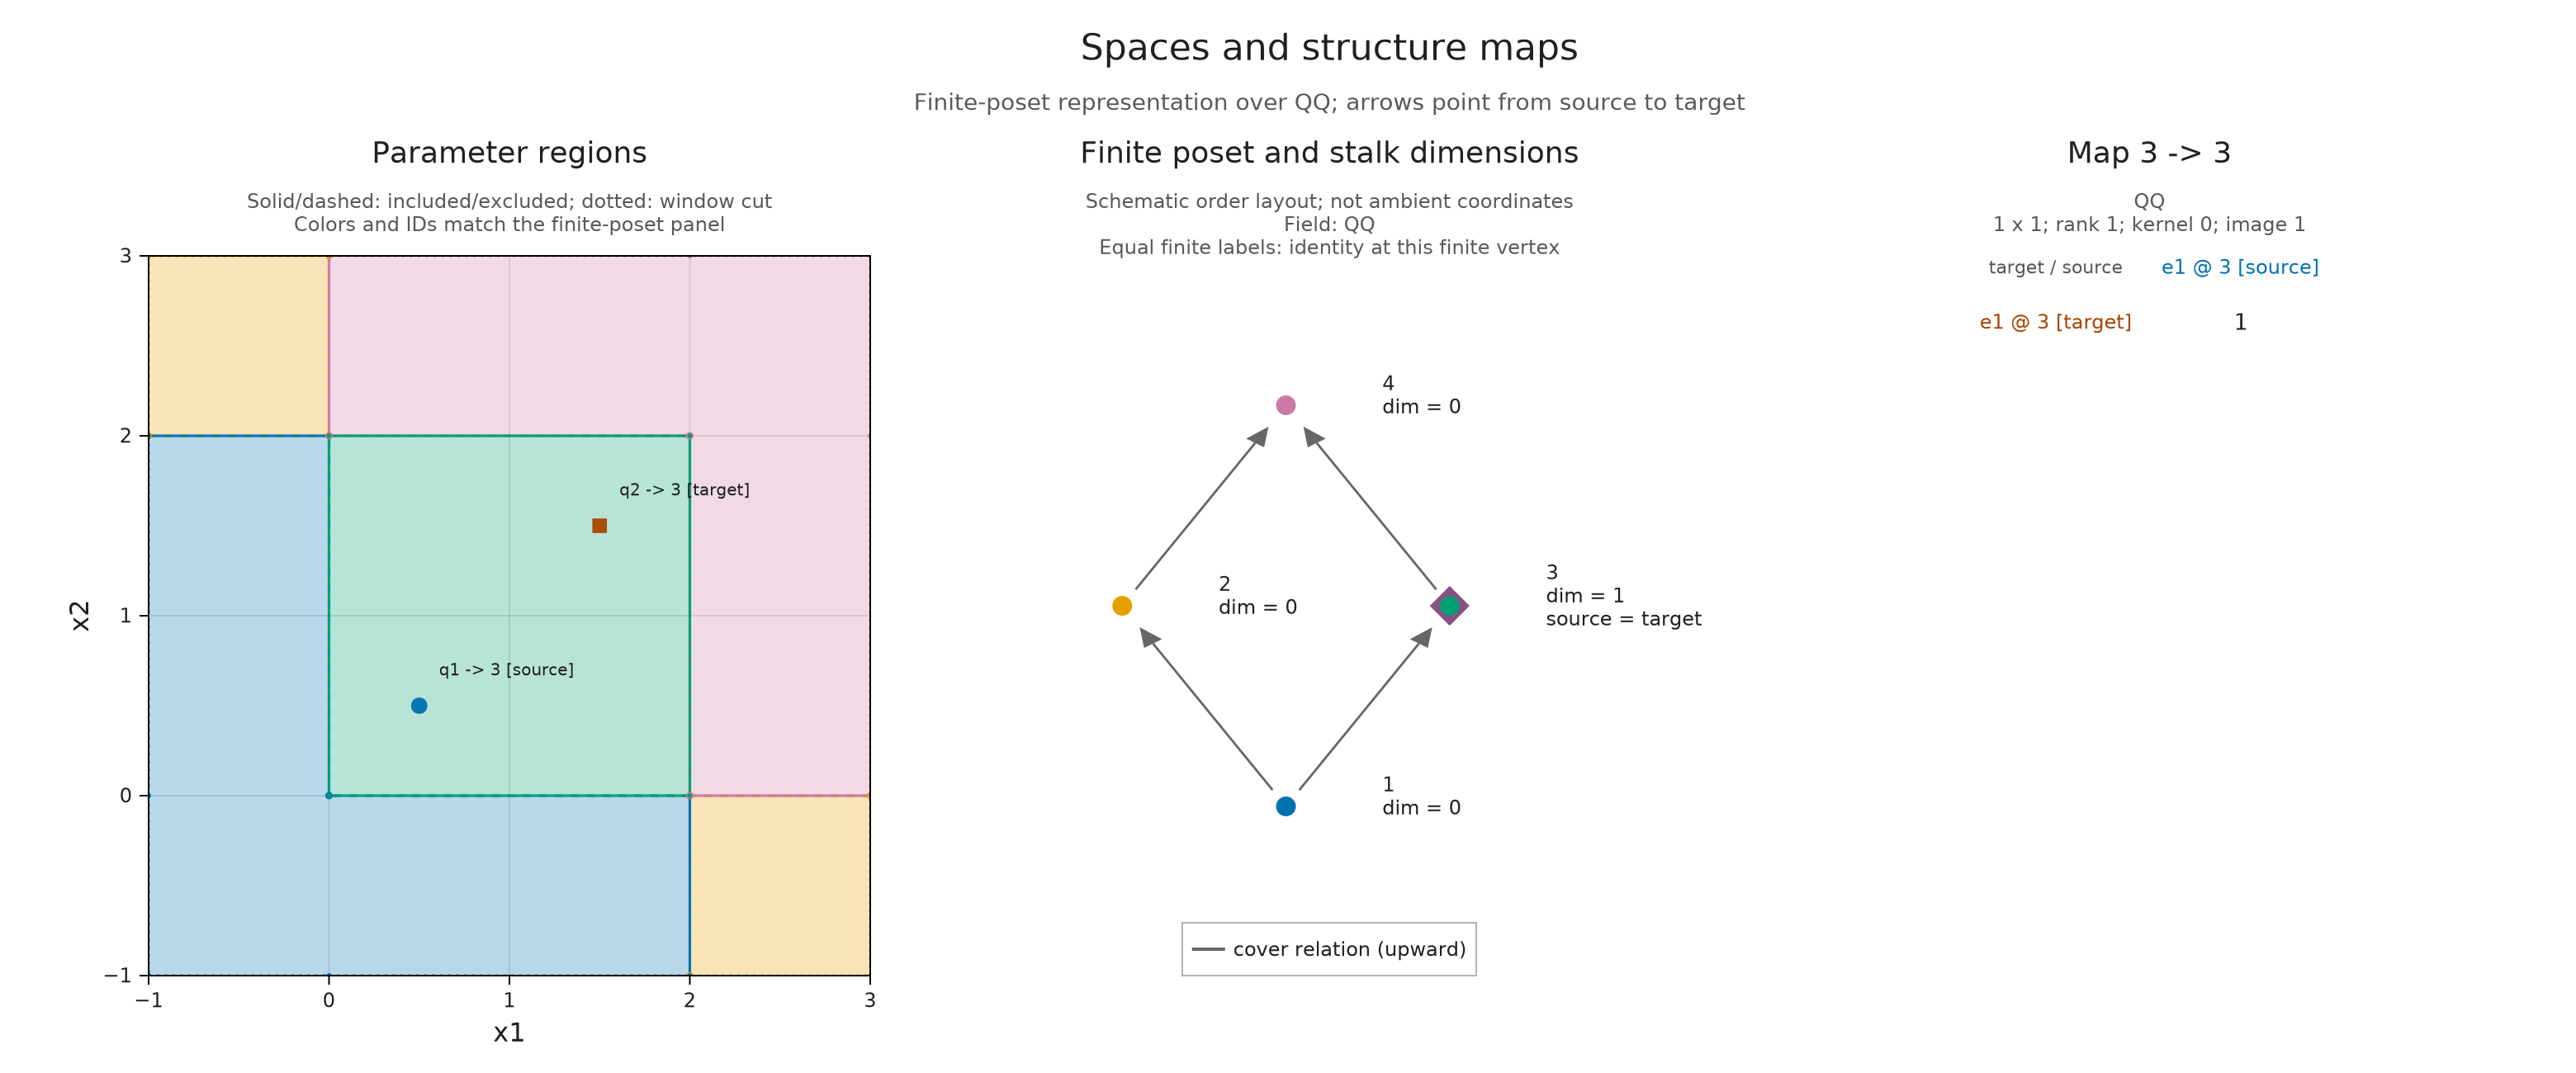

In [4]:
session = OP.inspection_session(enc; box=([-1, -1], [3, 3]))
A.select_inspection!(session; parameter_pair=(x, y))
inside = OP.visual_state(session)
OP.visualize(A.inspection_snapshot(session))


The closed upper edge deserves its own state. At $(2,1)$ the stalk is still one-dimensional. This is a statement made by the classifier, not a conclusion drawn from the width of the plotted line.


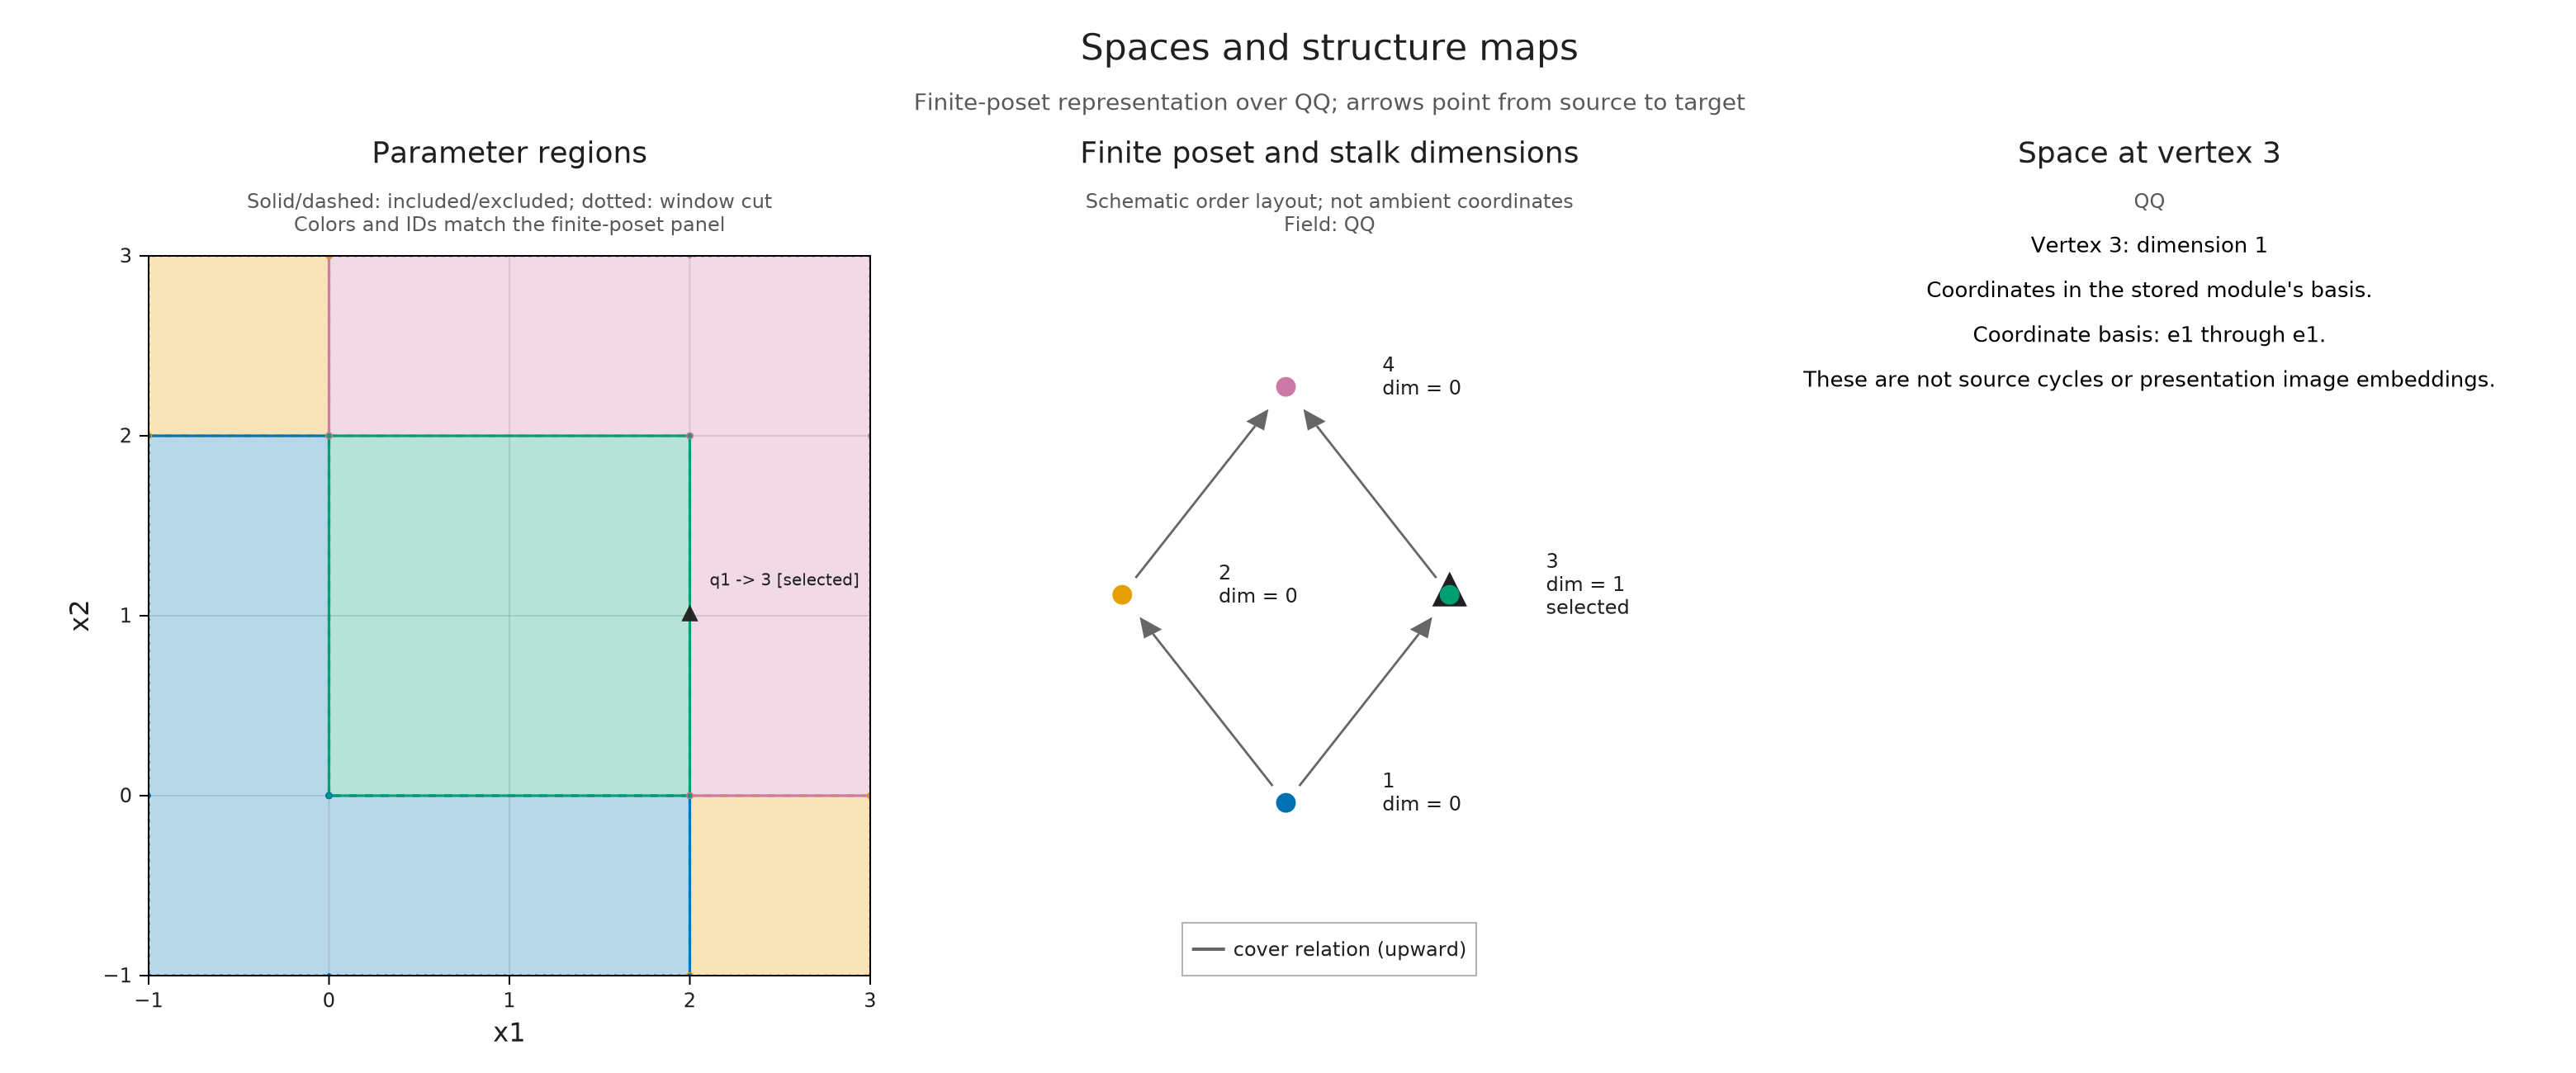

In [5]:
boundary_point = (2, 1)
qboundary = A.locate(classifier, boundary_point)
@assert dimensions[qboundary] == 1
A.select_inspection!(session; point=boundary_point)
boundary = OP.visual_state(session)
OP.visualize(A.inspection_snapshot(session))


Just beyond that edge, the stalk is zero. This encoding represents that zero space: its classifier still returns a finite label. A classifier returning `0` would instead mean that the parameter is outside its represented domain, and would not justify declaring the space zero.


In [6]:
outside_point = (5//2, 1//1)
qoutside = A.locate(classifier, outside_point)
@assert qoutside != 0 && dimensions[qoutside] == 0
A.select_inspection!(session; point=outside_point)
outside = OP.visual_state(session)
A.inspection_selection(session)


(vertex = 4, pair = nothing, query_points = ((5//2, 1//1),), parameter_relation = :not_applicable, selector = :point, input = :provided, revision = 3, view = :module, basis = false, upset = 1, downset = 1, slice = nothing, slice_scope = :window, interval = nothing)

## Keep the choices that explain your result

Name the three prepared states so the recipient can tell them apart. The JSON artifact below includes the mathematical encoding because we explicitly pass `object=enc`. Its identity must agree with the object captured by each resumable frame. Saving with that source also replays the supported selected requests to check their answers. The artifact can then restore the recorded views and resume supported queries in Julia.

The HTML file contains the same prepared states without the mathematical object. It embeds its drawings, state selector and machine-readable data. Someone can switch among those choices and inspect their retained values with Julia closed; they cannot ask for a fourth parameter through that offline file. The caption records what the selections mean.

We use a temporary directory so rerunning the lesson cannot overwrite your analysis. Replace `mktempdir()` with your own destination when keeping these files.


In [7]:
saved_directory = mktempdir()
json_path = joinpath(saved_directory, "square.json")
html_path = joinpath(saved_directory, "square.html")
frames = (inside=inside, boundary=boundary, outside=outside)
caption = "A rational square-supported module: an interior identity map, a closed boundary stalk, and a represented zero stalk."
OP.save_visual_session(json_path, frames; object=enc, selected=:inside, caption)
OP.save_visual_session(html_path, frames; selected=:inside, caption)
@assert isfile(json_path) && isfile(html_path)
(json=json_path, browser=html_path)


(json = "/tmp/jl_copye3/square.json", browser = "/tmp/jl_copye3/square.html")

Close the original session to release its callbacks and caches. Its final static snapshot remains available, but closing does not turn that same object back into a live session. Reopening starts from the saved record.


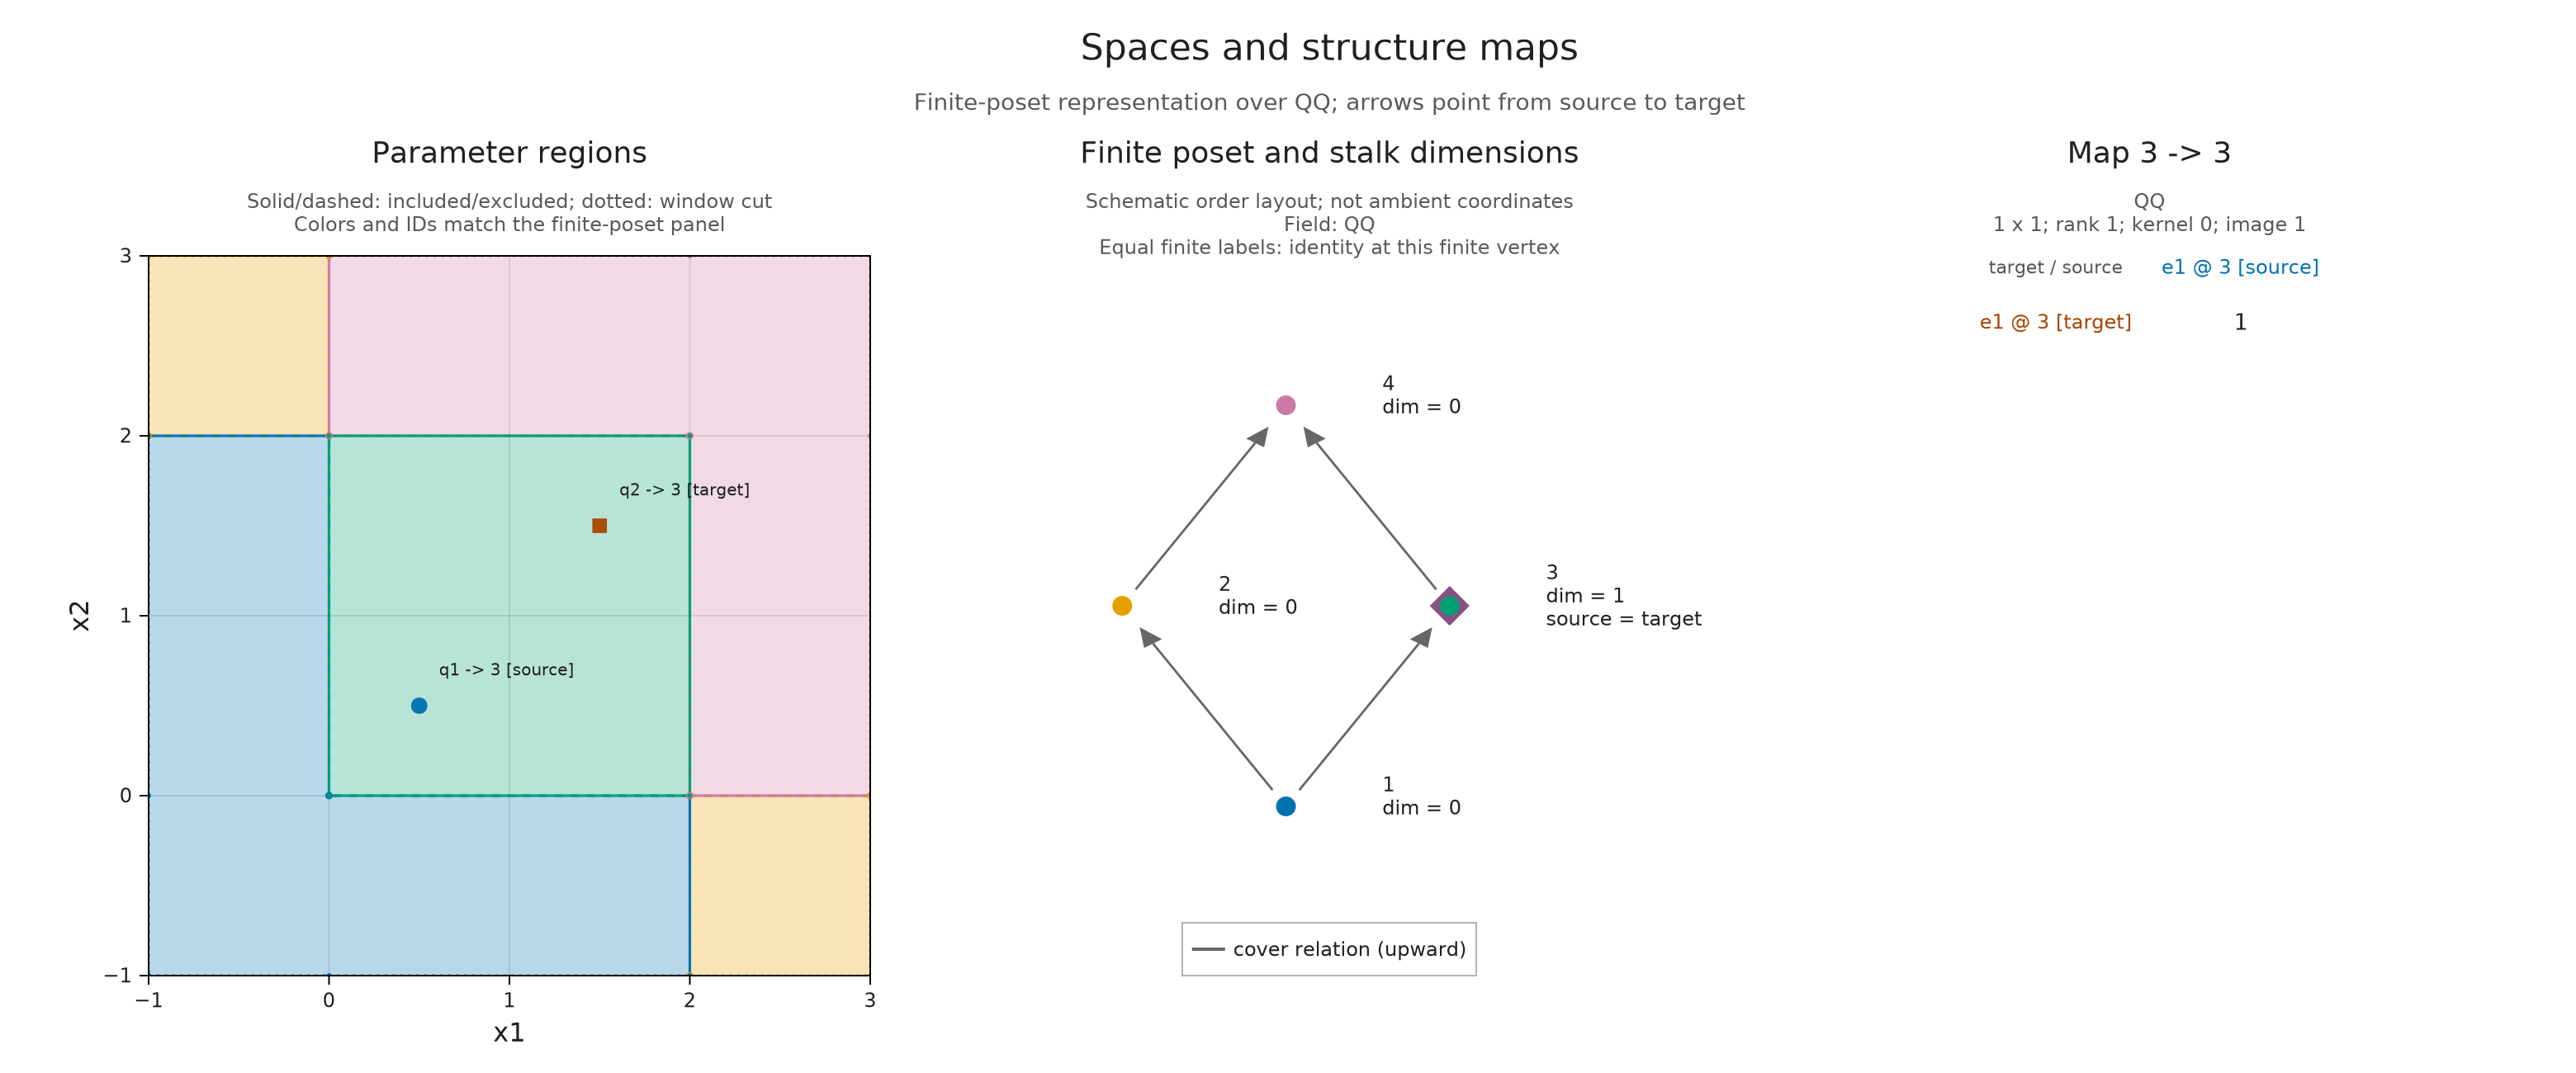

In [8]:
A.close_inspection!(session)
saved = OP.load_visual_session(json_path)
@assert Set(A.visual_session_states(saved)) == Set((:inside, :boundary, :outside))
@assert A.inspection_selection(saved; state=:inside).query_points == (x, y)
@assert A.inspection_selection(saved; state=:boundary).query_points == (boundary_point,)
@assert A.inspection_selection(saved; state=:outside).query_points == (outside_point,)
OP.visualize(saved; state=:inside)


The restored picture keeps the original selected coordinates and displayed matrix. A saved mathematical encoding and a saved view answer different questions: the former supports mathematical queries, while the latter also preserves the presentation of a particular answer. The saved-view format retains the coordinates needed to resume this supported inspector consistently.

To try the offline result, open the printed `square.html` path in a browser. Choose **boundary** and **outside** and compare their stalk readouts. The exact values remain available with the artifact; browser drawing coordinates are numerical display coordinates.

## Ask a new question in Julia

The embedded encoding allows a new live session. It reconstructs the supported request and selected state; it does not revive serialized callbacks or reuse the old cache. Its new selection can therefore differ from every prepared offline state.

Before running this cell, predict the dimension at $(1/3,1/3)$. Does the answer require adding another prepared HTML state?


In [9]:
resumed = OP.inspection_session(saved; state=:inside)
new_point = (1//3, 1//3)
A.select_inspection!(resumed; point=new_point)
@assert A.inspection_selection(resumed).query_points == (new_point,)
@assert dimensions[A.locate(classifier, new_point)] == 1
A.inspection_selection(resumed)


(vertex = 3, pair = nothing, query_points = ((1//3, 1//3),), parameter_relation = :not_applicable, selector = :point, input = :provided, revision = 2, view = :module, basis = false, upset = 1, downset = 1, slice = nothing, slice_scope = :window, interval = nothing)

The new stalk is one-dimensional because the parameter lies inside the square. Julia can compute this selection from the embedded encoding; the offline HTML continues to offer its three saved states. To share the new answer, freeze it with `visual_state` and save a new collection.


In [10]:
A.close_inspection!(resumed)
nothing


## Optional: preserve an ordinary interval and its representative

An ordinary persistence diagram is another legitimate starting object; this direct routine does not construct a finite encoding. In the $3\times3$ image below, the boundary enters at zero and the centre at five. Its degree-one interval is $[0,5)$: a loop exists before the central square fills it.

We request representatives during persistence computation. Selecting an interval later cannot create a cycle that was never retained. A group collects equal decorated intervals; `member=1` identifies the original member whose representative we want.


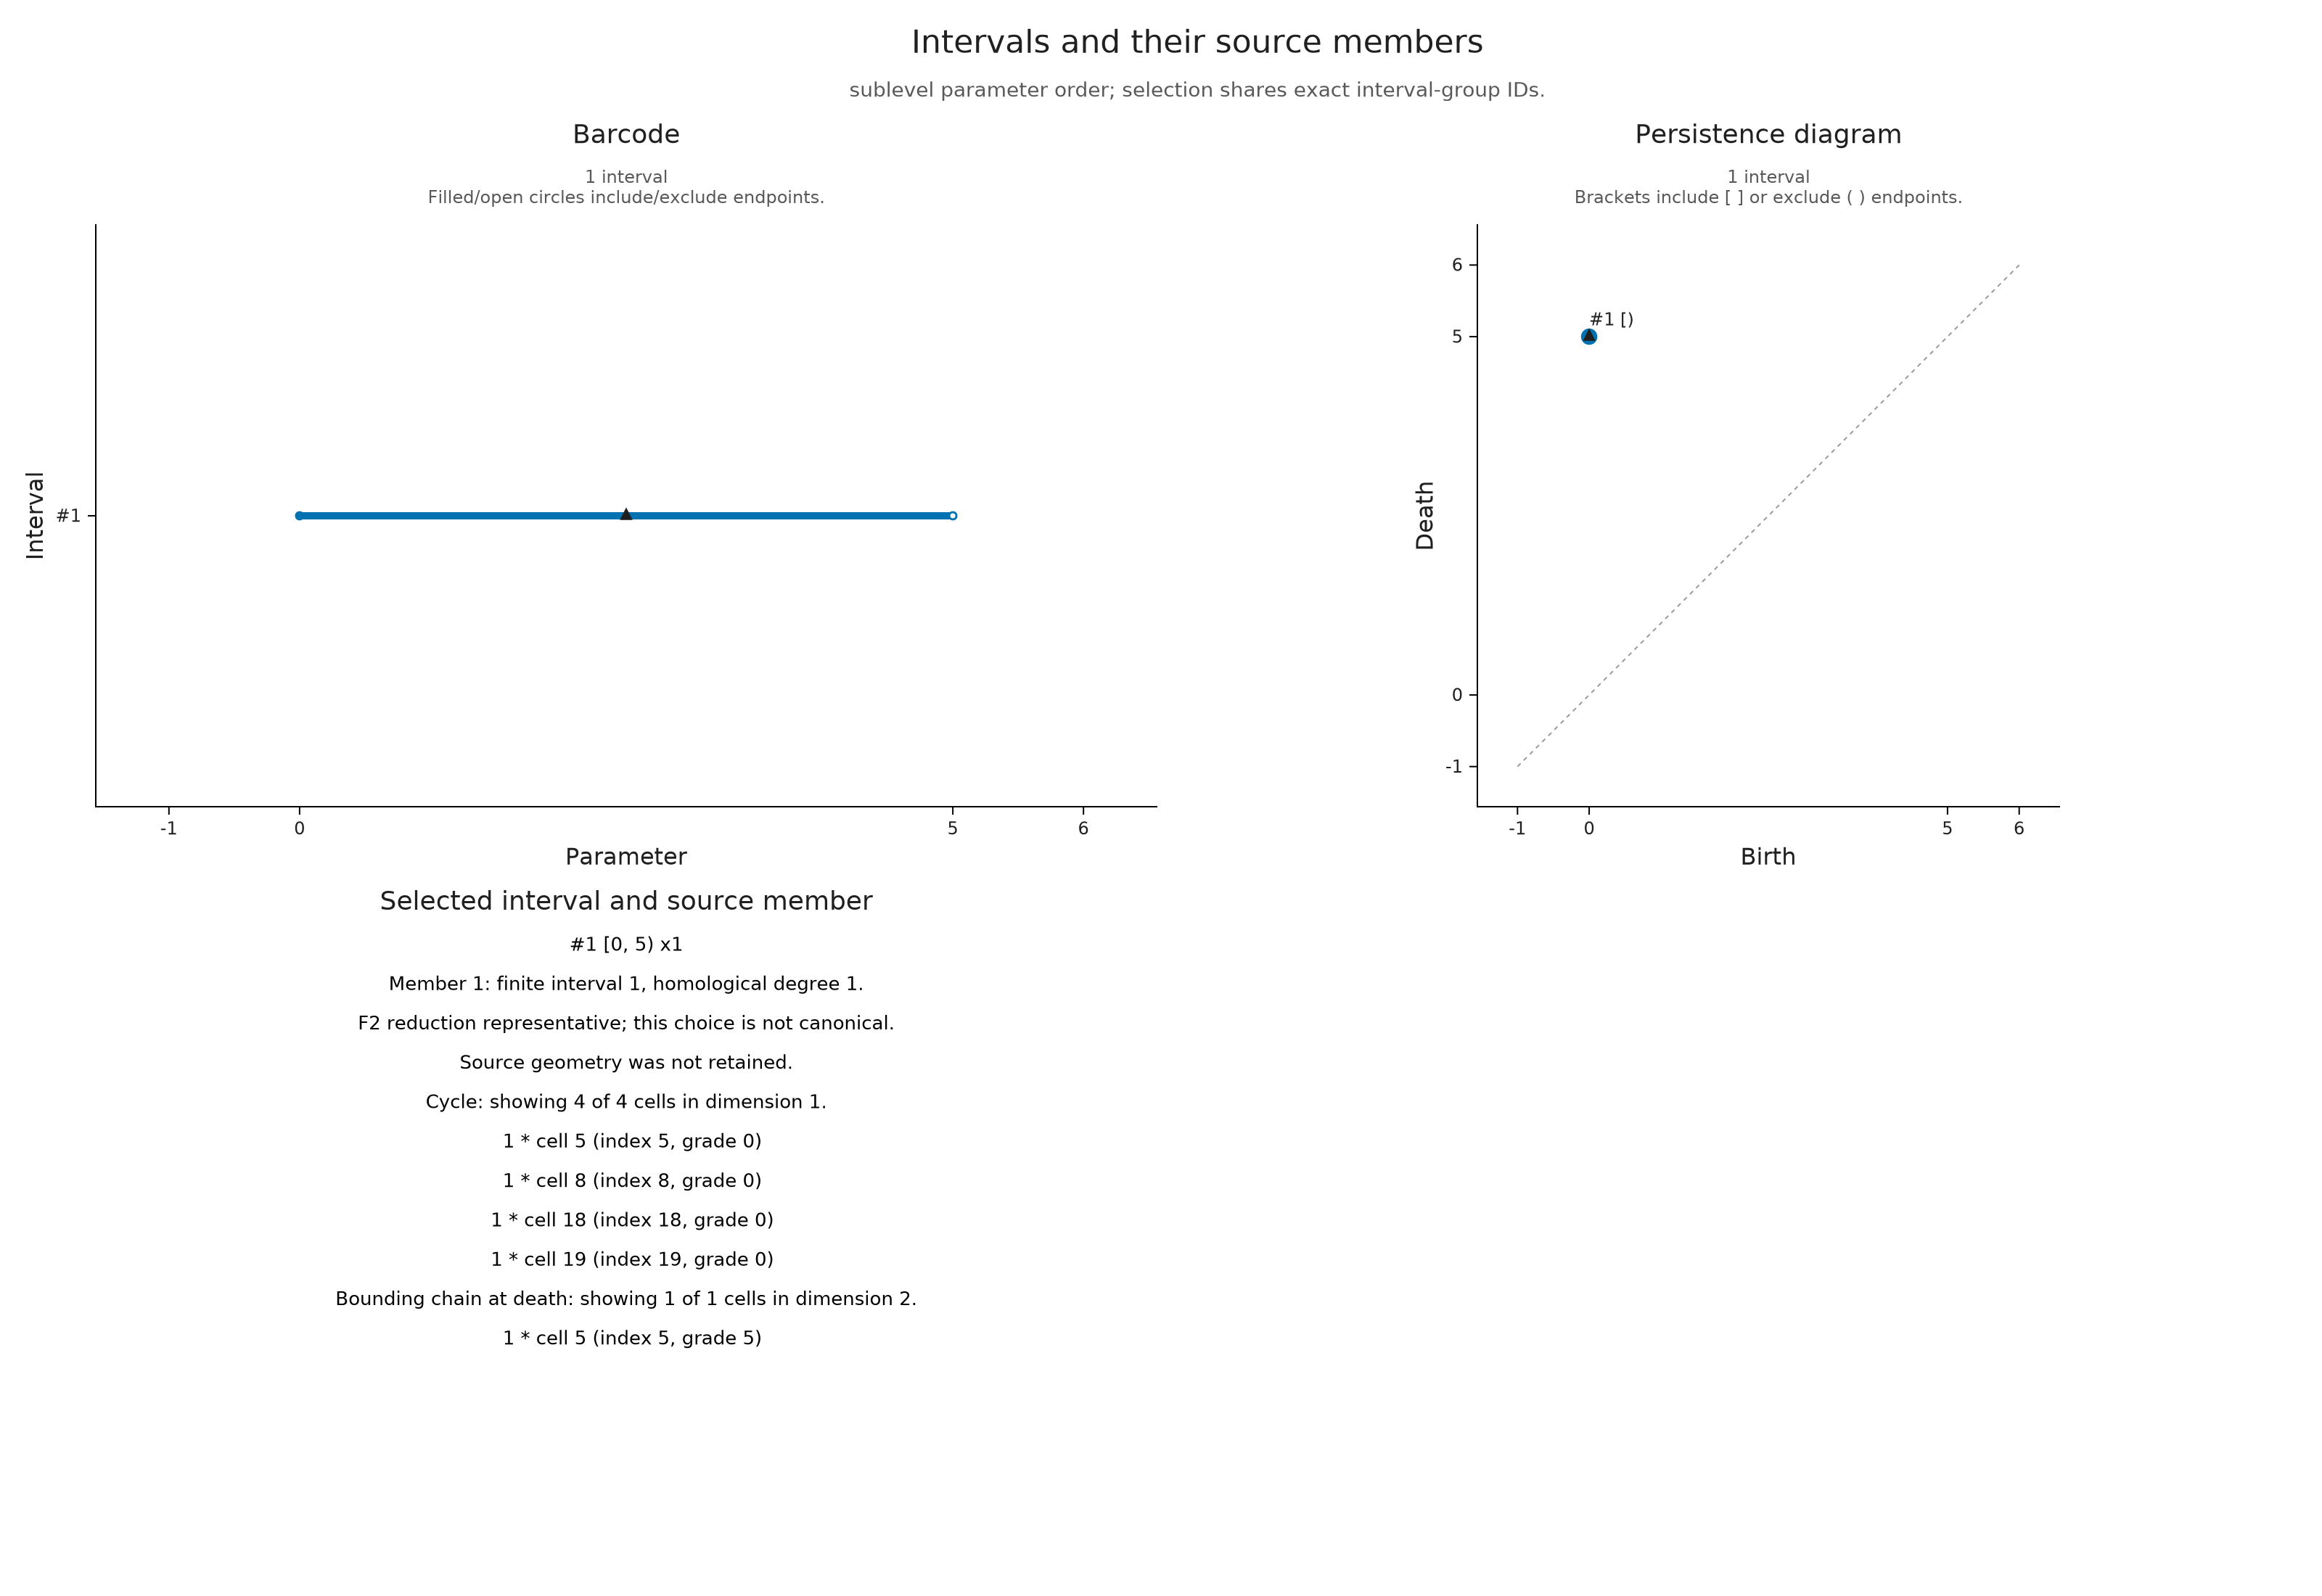

In [11]:
image_values = zeros(Int, 3, 3)
image_values[2, 2] = 5
diagram = OP.cubical_persistence(image_values; representatives=true)
interval_session = OP.inspection_session(diagram; dim=1, window=(-1, 6))
A.select_inspection!(interval_session; interval=1, member=1, representative=true)
ring_path = joinpath(saved_directory, "ring.html")
OP.save_visual_session(ring_path, interval_session; object=diagram,
    caption="The degree-one image-ring interval [0,5), with its retained reduction representative.")
A.close_inspection!(interval_session)
ring_saved = OP.load_visual_session(ring_path)
ring_selection = A.inspection_selection(ring_saved)
@assert ring_selection.interval == 1 && ring_selection.member == 1
@assert ring_selection.representative
OP.visualize(ring_saved)


The endpoint, member identity and retained coefficient data belong to the saved mathematical record. The cycle is a reduction choice, not a canonical generator. Retained cell identifiers alone do not establish a geometric embedding; source overlays need their own retained and checked correspondence.

Because this file also embeds its supported diagram, it can open a new interval inspector in Julia. Selection reuses the retained persistence result rather than recomputing persistent homology.


In [12]:
ring_resumed = OP.inspection_session(ring_saved)
@assert A.inspection_selection(ring_resumed).interval == 1
@assert A.inspection_selection(ring_resumed).representative
A.close_inspection!(ring_resumed)
nothing


## Decide what the recipient needs

| Intended use | What to preserve |
| --- | --- |
| View one selected figure | A static figure export, with its interpretation |
| Switch among prepared selections without Julia | A saved HTML session containing those named states |
| Inspect exact recorded selections and plotted values | A saved visual-session artifact and its data |
| Ask new supported questions in Julia | A saved session with its mathematical object explicitly included or referenced |

Frames contain prepared outputs, so saving many large views costs space even when they share an underlying object. Resumable captures also identify the complete source, and saving an attached source validates its selected answers. If you only need a portable figure, `visual_state(A.inspection_snapshot(session); selection=A.inspection_selection(session))` captures that static specification and selected data without a live-restoration request or full-source fingerprint. Retain the states that explain the result; keep new exploratory computation in Julia. Some mathematical objects support portable snapshots without supporting live restoration. The [session reference](../src/reference/visual_sessions.md) gives the precise boundary.

For a short procedure starting from a retained ordinary interval, use [Save a selection and reopen a supported offline view](../recipes/reopen_session.md). For combining the selected result with annotations and shared scales, continue with [Composing, exporting and reopening selected results](compose_figures.ipynb).

The following optional cell removes only the temporary directory created by this notebook. Run it after you have finished inspecting the saved files.


In [13]:
rm(saved_directory; recursive=true)
nothing


To construct or repair the finite input itself, continue with [constructing modules without a filtration](presentations.ipynb). Its editor separates an editable draft from a checked mathematical object.
